# Finding and fitting two planets in Gaia astrometry

This notebook
1. simulates Gaia DR5 epoch astrometry of a star with two giant planets,
2. searches for planets without assuming how many there are,
3. plots each planet's orbit on the sky and its along-scan signal, with the other planet subtracted, and
4. samples the posterior with MCMC ([emcee](https://emcee.readthedocs.io)) and shows corner plots for both planets.

It needs `gaiamockplus`, `emcee` and `corner`. The MCMC takes about 5 minutes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
import gaiamockplus as gmp
from gaiamockplus import gaiamock

%config InlineBackend.figure_format = 'retina'

c_funcs = gaiamock.read_in_C_functions()  # compiled functions used by gaiamock's routines
rng = np.random.default_rng(29)           # random numbers for the simulation (reproducible)
M_JUP = 1/1047.57                         # Jupiter mass in Msun

## 1. Simulate the epoch astrometry

A Sun-like star at 50 pc hosts two giant planets, of 10 and 6 $M_\mathrm{J}$, with periods of 1.2 and 7 yr, so that both orbits are well covered by the ~10.5 yr DR5 baseline. The system is designed to be dynamically stable: the period ratio is 5.8, the eccentricities are modest (0.1 and 0.2), and the orbits are nearly coplanar (mutual inclination 6°). By the Hill-stability criterion of Gladman (1993), in the form of Barnes & Greenberg (2006), $\beta/\beta_\mathrm{crit} = 1.18 > 1$.

The planets' signals add: the star's reflex motion is the sum of one Keplerian orbit per planet (planet-planet interactions are neglected).

In [2]:
# the star: a Sun-like star at 50 pc
m_star = 1.0               # Msun
parallax = 20.0            # mas
phot_g_mean_mag = 8.1      # G magnitude of such a star at 50 pc
ra, dec = 200.0, 35.0      # deg
pmra, pmdec = -25.0, 15.0  # mas/yr

# the planets (b: inner, c: outer)
planets = [dict(period=1.2*365.25, Tp=200.0, ecc=0.1, Omega=np.radians(100.0), inc=np.radians(50.0), w=np.radians(30.0), m_planet=10*M_JUP),
           dict(period=7.0*365.25, Tp=900.0, ecc=0.2, Omega=np.radians(105.0), inc=np.radians(55.0), w=np.radians(120.0), m_planet=6*M_JUP)]
names = ['b', 'c']

data = gmp.predict_astrometry_planets(ra=ra, dec=dec, parallax=parallax, pmra=pmra, pmdec=pmdec, m_star=m_star,
                                      planets=planets, phot_g_mean_mag=phot_g_mean_mag, data_release='dr5',
                                      c_funcs=c_funcs, rng=rng)
t_ast_yr, psi, plx_factor, ast_obs, ast_err = data

a0_true = gmp.get_planet_a0_mas(m_star, planets, parallax)
print(f'{len(t_ast_yr)} field-of-view transits; median uncertainty {np.median(ast_err):.3f} mas')
for name, planet, a0 in zip(names, planets, a0_true):
    print(f'planet {name}: P = {planet["period"]/365.25:.1f} yr, star\'s reflex semimajor axis a0 = {a0:.3f} mas')

204 field-of-view transits; median uncertainty 0.080 mas
planet b: P = 1.2 yr, star's reflex semimajor axis a0 = 0.214 mas
planet c: P = 7.0 yr, star's reflex semimajor axis a0 = 0.418 mas


## 2. Search for planets

Without `n_planets`, `fit_astrometry_planets` runs a blind search: it adds planets one at a time, each found with gaiamock's search while the planets already found are included in the model, and keeps a new planet only if it lowers $\chi^2$ by more than `delta_chi2_min` (default 50). After each new planet, all planets are polished jointly and each is searched for again with the others held fixed. The search stops at the first planet that does not pass the threshold (or at `max_planets`, default 3).

In [3]:
res = gmp.fit_astrometry_planets(*data, m_star=m_star)

print(f"planets found: {res['n_planets']}")
print('chi2 for 0, 1, 2 planets:', np.round(res['chi2_history'], 1))
for name, p in zip(names, res['planets']):
    print(f"planet {name}: P = {p['period']:.1f} d; chi2 increase if it is removed: {p['delta_chi2']:.0f}")
rejected = res['rejected_candidate']
print(f"the best three-planet model (P = {', '.join(f'{P:.0f}' for P in rejected['periods'])} d) would lower chi2 by only "
      f"{rejected['delta_chi2']:.1f} < 50, so a third planet is not included")

planets found: 2
chi2 for 0, 1, 2 planets: [2521.8  709.   253.1]
planet b: P = 439.5 d; chi2 increase if it is removed: 456
planet c: P = 2550.6 d; chi2 increase if it is removed: 1396
the best three-planet model (P = 57, 440, 2579 d) would lower chi2 by only 26.9 < 50, so a third planet is not included


In [4]:
# compare with the truth
print(f"parallax [mas]: true {parallax:.3f}, fit {res['parallax']:.3f} +/- {res['sig_parallax']:.3f}")
for name, planet, fit, a0 in zip(names, planets, res['planets'], a0_true):
    rows = [('P [yr]', planet['period']/365.25, fit['period']/365.25, fit['sig_period']/365.25),
            ('e', planet['ecc'], fit['ecc'], fit['sig_ecc']),
            ('a0 [mas]', a0, fit['a0_mas'], fit['sig_a0_mas']),
            ('m_p [M_Jup]', planet['m_planet']/M_JUP, fit['m_planet']/M_JUP, fit['sig_m_planet']/M_JUP),
            ('inc [deg]', np.degrees(planet['inc']), np.degrees(fit['inc']), np.degrees(fit['sig_inc'])),
            ('w [deg]', np.degrees(planet['w']), np.degrees(fit['w']), np.degrees(fit['sig_w'])),
            ('Omega [deg]', np.degrees(planet['Omega']), np.degrees(fit['Omega']), np.degrees(fit['sig_Omega']))]
    print(f"\nplanet {name}      {'true':>8s} {'fit':>16s}")
    for label, true, value, sigma in rows:
        print(f'{label:15s} {true:8.3f} {value:8.3f} +/- {sigma:.3f}')

parallax [mas]: true 20.000, fit 19.993 +/- 0.012

planet b          true              fit
P [yr]             1.200    1.203 +/- 0.003
e                  0.100    0.174 +/- 0.085
a0 [mas]           0.214    0.222 +/- 0.013
m_p [M_Jup]       10.000   10.350 +/- 0.605
inc [deg]         50.000   50.509 +/- 5.059
w [deg]           30.000   43.681 +/- 32.892
Omega [deg]      100.000   99.224 +/- 6.474

planet c          true              fit
P [yr]             7.000    6.983 +/- 0.058
e                  0.200    0.177 +/- 0.053
a0 [mas]           0.418    0.408 +/- 0.014
m_p [M_Jup]        6.000    5.874 +/- 0.200
inc [deg]         55.000   54.327 +/- 2.683
w [deg]          120.000  125.699 +/- 17.466
Omega [deg]      105.000  107.296 +/- 3.082


## 3. Each planet's orbit and along-scan signal

To isolate the evidence for each planet, the best-fit signal of the *other* planet is subtracted from the data. `astrometry_planets_model` with `return_components=True` gives the best-fit model and each planet's along-scan signal (from `res['model_planets']`, the fitted planets in the format of the models).

The sky plots (gaiamock's `plot_2d_orbit_and_residuals`) are as in notebook 01: each measurement is placed at its planet's best-fit orbit position, offset by its residual along the scan direction.

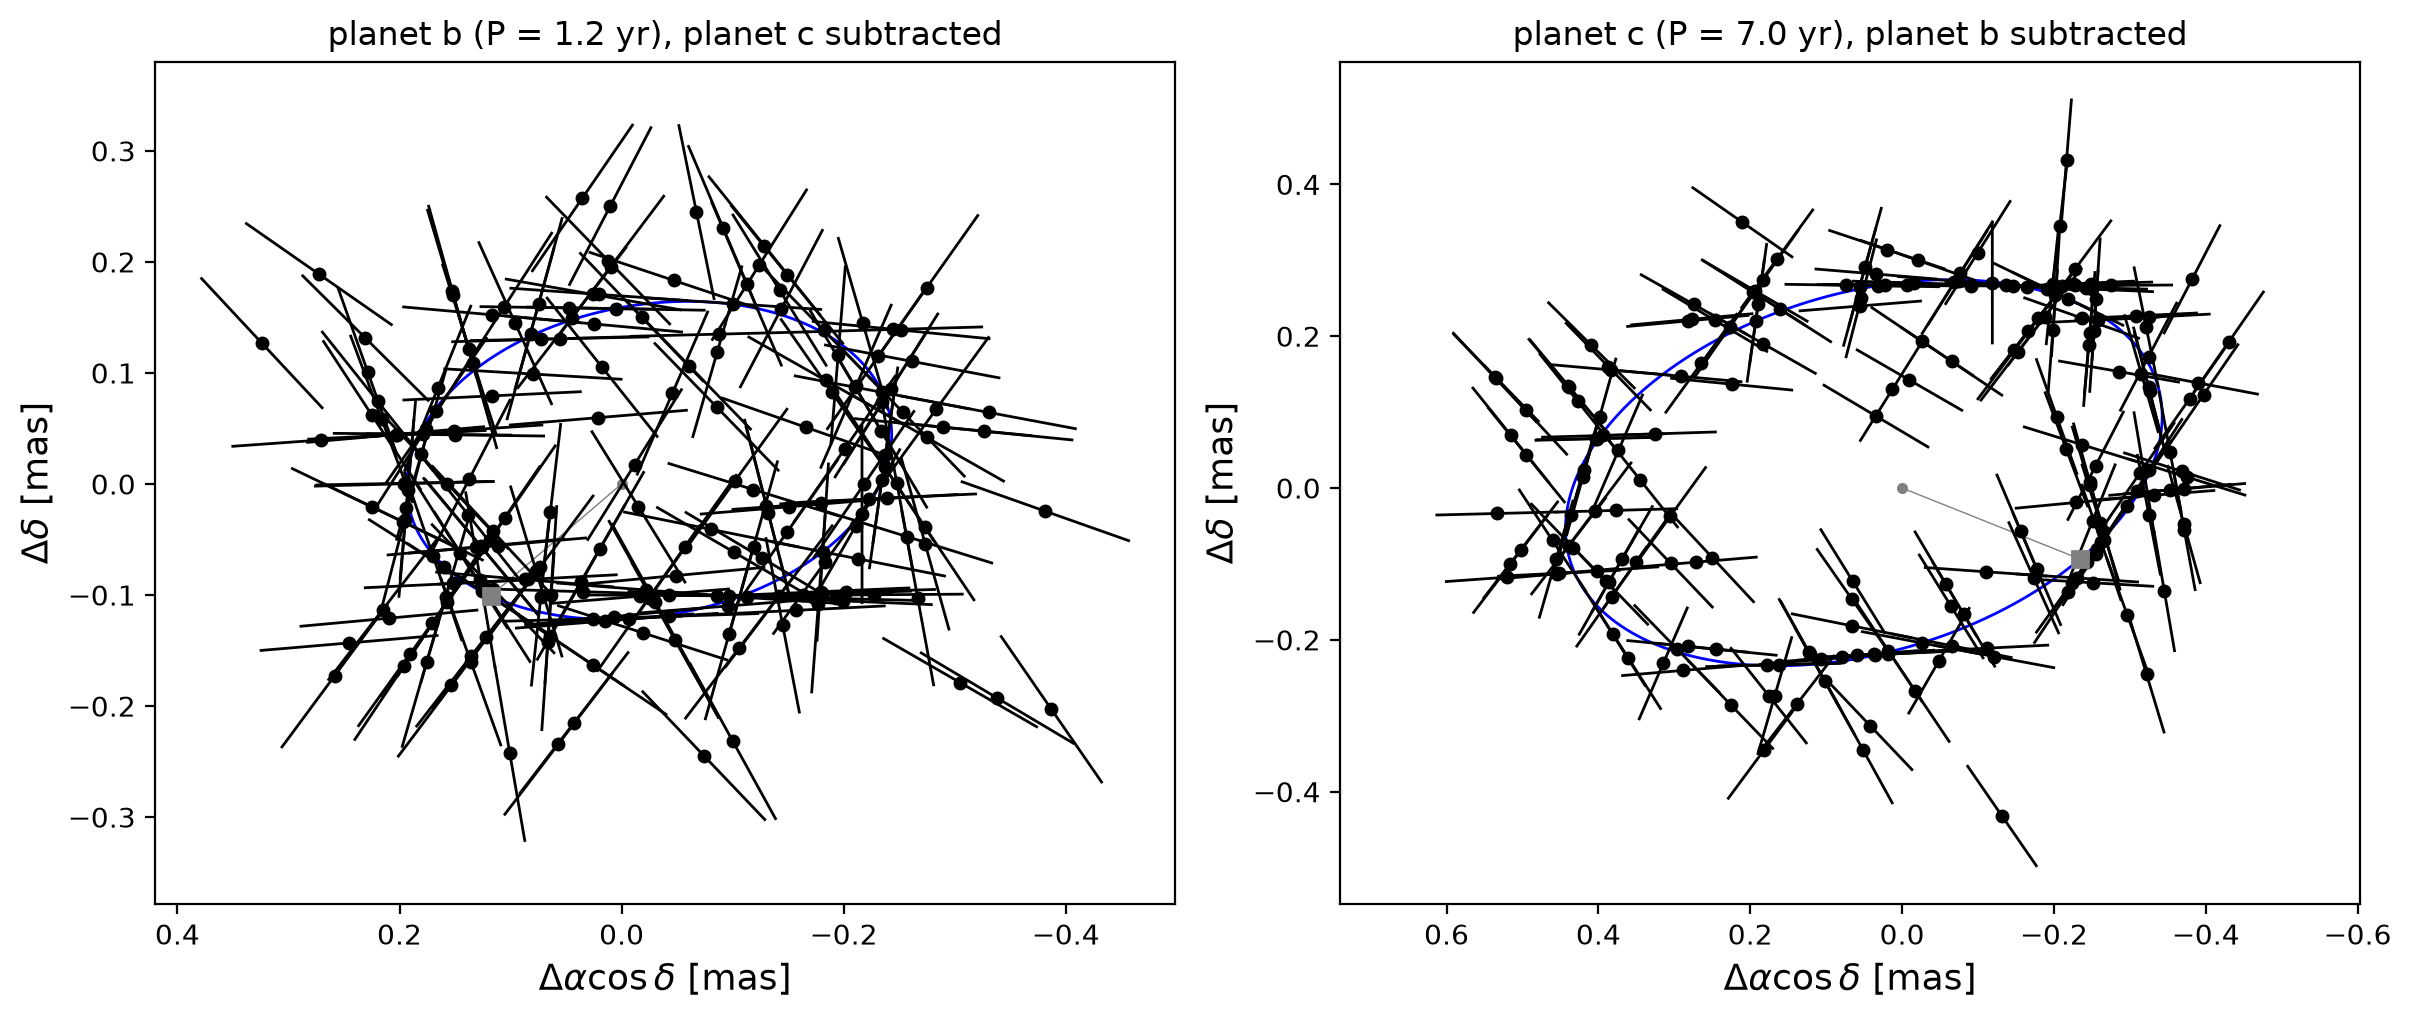

In [5]:
model, components = gmp.astrometry_planets_model(t_ast_yr, psi, plx_factor, res['ra_off'], res['dec_off'], res['parallax'],
                                                 res['pmra'], res['pmdec'], m_star, res['model_planets'], c_funcs,
                                                 return_components=True)
star = model - components.sum(axis=0)  # position, parallax and proper motion part of the model

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for i, (ax, fit) in enumerate(zip(axes, res['planets'])):
    gaiamock.plot_2d_orbit_and_residuals(t_ast_yr, psi, plx_factor, ast_obs - components[1 - i], ast_err,
                                         period=fit['period'], ecc=fit['ecc'], Tp=fit['Tp'], delta_ra=res['ra_off'],
                                         delta_dec=res['dec_off'], parallax=res['parallax'], pmra=res['pmra'], pmdec=res['pmdec'],
                                         A=fit['A'], B=fit['B'], F=fit['F'], G=fit['G'], data_release='dr5', c_funcs=c_funcs, ax=ax)
    ax.set_aspect('equal', adjustable='datalim')
    ax.set_xlabel(r'$\Delta\alpha\cos\delta$ [mas]', fontsize=13)
    ax.set_ylabel(r'$\Delta\delta$ [mas]', fontsize=13)
    ax.set_title(f'planet {names[i]} (P = {fit["period"]/365.25:.1f} yr), planet {names[1 - i]} subtracted', fontsize=12)
plt.tight_layout()
plt.show()

Along the scan direction, the data with the star's motion and the other planet subtracted (black) follow each planet's best-fit signal (red circles; the model at each measurement, which jumps between measurements because the scan angle changes). The bottom panel shows the residuals of the full two-planet model.

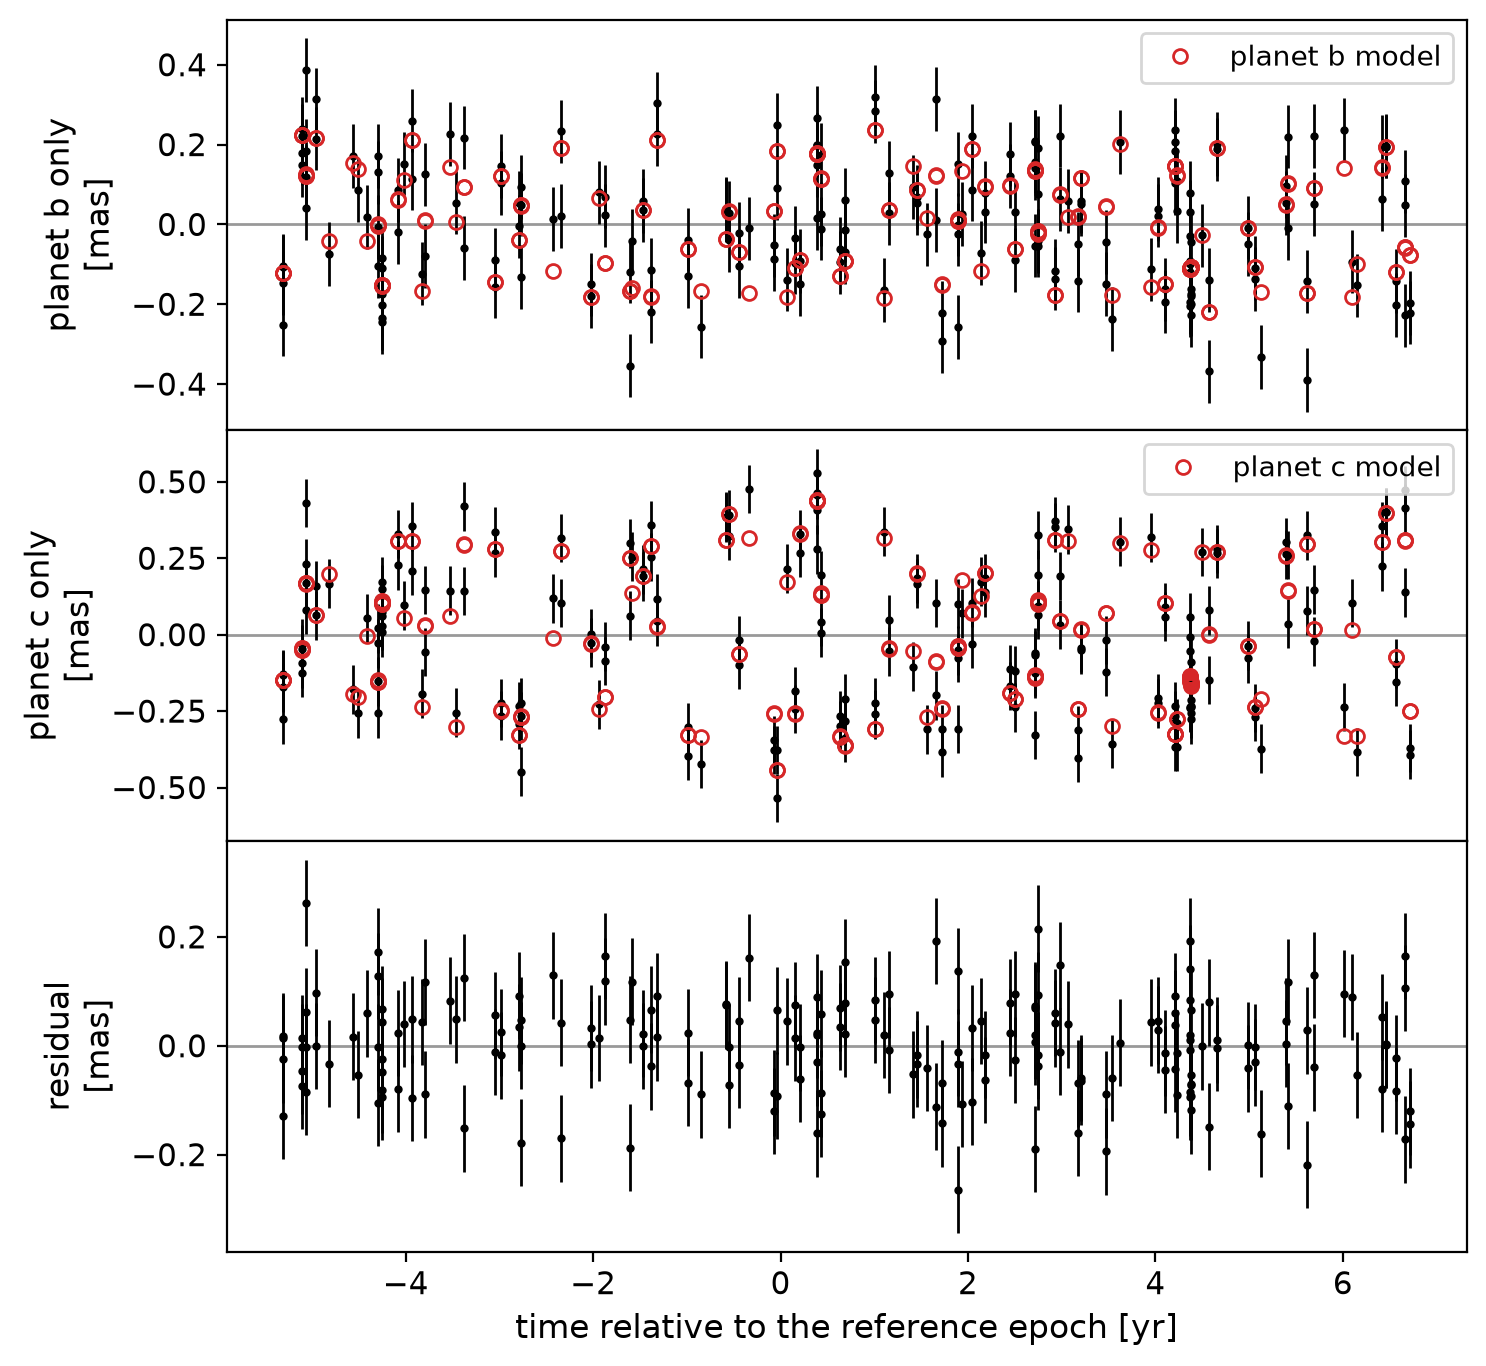

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(8, 8), sharex=True, gridspec_kw=dict(hspace=0))
for i, ax in enumerate(axes[:2]):
    ax.errorbar(t_ast_yr, ast_obs - star - components[1 - i], ast_err, fmt='k.', ms=4, lw=1, zorder=1)
    ax.plot(t_ast_yr, components[i], 'o', mfc='none', mec='C3', ms=5, zorder=2, label=f'planet {names[i]} model')
    ax.set_ylabel(f'planet {names[i]} only\n[mas]', fontsize=12)
    ax.legend(loc='upper right', fontsize=10)
axes[2].errorbar(t_ast_yr, ast_obs - model, ast_err, fmt='k.', ms=4, lw=1)
axes[2].set_ylabel('residual\n[mas]', fontsize=12)
axes[2].set_xlabel('time relative to the reference epoch [yr]', fontsize=12)
for ax in axes:
    ax.axhline(0, color='0.6', lw=1, zorder=0)
    ax.tick_params(labelsize=11)
plt.show()

## 4. MCMC

As in notebook 01, `log_likelihood_astrometry_planets` takes a parameter vector ordered like `res['theta']`, now with 7 orbital parameters per planet (19 in total). The priors are uniform; with several planets, ordering the periods ($P_b < P_c$) keeps the walkers from swapping the planets. As in notebook 01, the likelihood includes an astrometric jitter $s$ (the last parameter, uniform prior on [0, 0.5) mas), started at the value that makes the best fit's reduced $\chi^2$ 1. With 20 strongly correlated parameters, the autocorrelation time is long (thousands of steps), so the chain must be long too: here it is about 30 autocorrelation times, enough for the posterior summaries below (emcee suggests more than 50 for a precise estimate of the autocorrelation time itself, which would take about twice as long).

In [7]:
print(res['theta_names'] + ['ast_jitter'])

def log_prior(theta):
    plx, periods, eccs, s = theta[2], theta[5:19:7], theta[6:19:7], theta[-1]
    if (0 < plx and np.all((10 < periods) & (periods < 1e4)) and np.all((0 <= eccs) & (eccs < 1)) and periods[0] < periods[1]
            and 0 <= s < 0.5):
        return 0.0
    return -np.inf

def log_prob(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + gmp.log_likelihood_astrometry_planets(theta, t_ast_yr, psi, plx_factor, ast_obs, ast_err, fit_ast_jitter=True)

s0 = gmp.estimate_astrometric_jitter(res, ast_err)
print(f'starting astrometric jitter: {1e3*s0:.1f} microarcsec')
nwalkers, nsteps = 48, 150000
p0 = gmp.initial_walkers(res, nwalkers, log_prob=log_prior, ast_jitter=s0, rng=rng)
np.random.seed(29)  # emcee draws its moves from numpy's global random state
sampler = emcee.EnsembleSampler(nwalkers, p0.shape[1], log_prob)
sampler.run_mcmc(p0, nsteps, progress=True);

['ra_off', 'dec_off', 'parallax', 'pmra', 'pmdec', 'period_0', 'ecc_0', 'phi_p_0', 'A_0', 'B_0', 'F_0', 'G_0', 'period_1', 'ecc_1', 'phi_p_1', 'A_1', 'B_1', 'F_1', 'G_1', 'ast_jitter']
starting astrometric jitter: 48.3 microarcsec


In [8]:
# convergence: the chain should be much longer than the autocorrelation time (tol=0: estimate it whatever the chain length)
tau = sampler.get_autocorr_time(tol=0)
print('autocorrelation times [steps]:', ', '.join(f'{n} {t:.0f}' for n, t in zip(res['theta_names'] + ['ast_jitter'], tau)))
print(f'chain length / longest autocorrelation time = {nsteps/tau.max():.0f}')

# discard the burn-in (5 autocorrelation times) and thin the chain
burn, thin = int(5*tau.max()), int(tau.max()/2)
samples = sampler.get_chain(discard=burn, thin=thin, flat=True)
print(f'{len(samples)} samples after discarding {burn} steps of burn-in and thinning by {thin}')

autocorrelation times [steps]: ra_off 3124, dec_off 2722, parallax 1284, pmra 1348, pmdec 1183, period_0 1350, ecc_0 1745, phi_p_0 5103, A_0 3911, B_0 4611, F_0 4412, G_0 3925, period_1 1520, ecc_1 2251, phi_p_1 5369, A_1 4683, B_1 4840, F_1 4516, G_1 4166, ast_jitter 1315
chain length / longest autocorrelation time = 28
2160 samples after discarding 26846 steps of burn-in and thinning by 2684


## 5. Corner plots

For each planet, the physical parameters are computed for each sample, as in notebook 01: the Campbell elements from the Thiele-Innes elements, and the planet mass from $a_0$, $P$, $\varpi$ and the stellar mass. The red lines mark the true values.

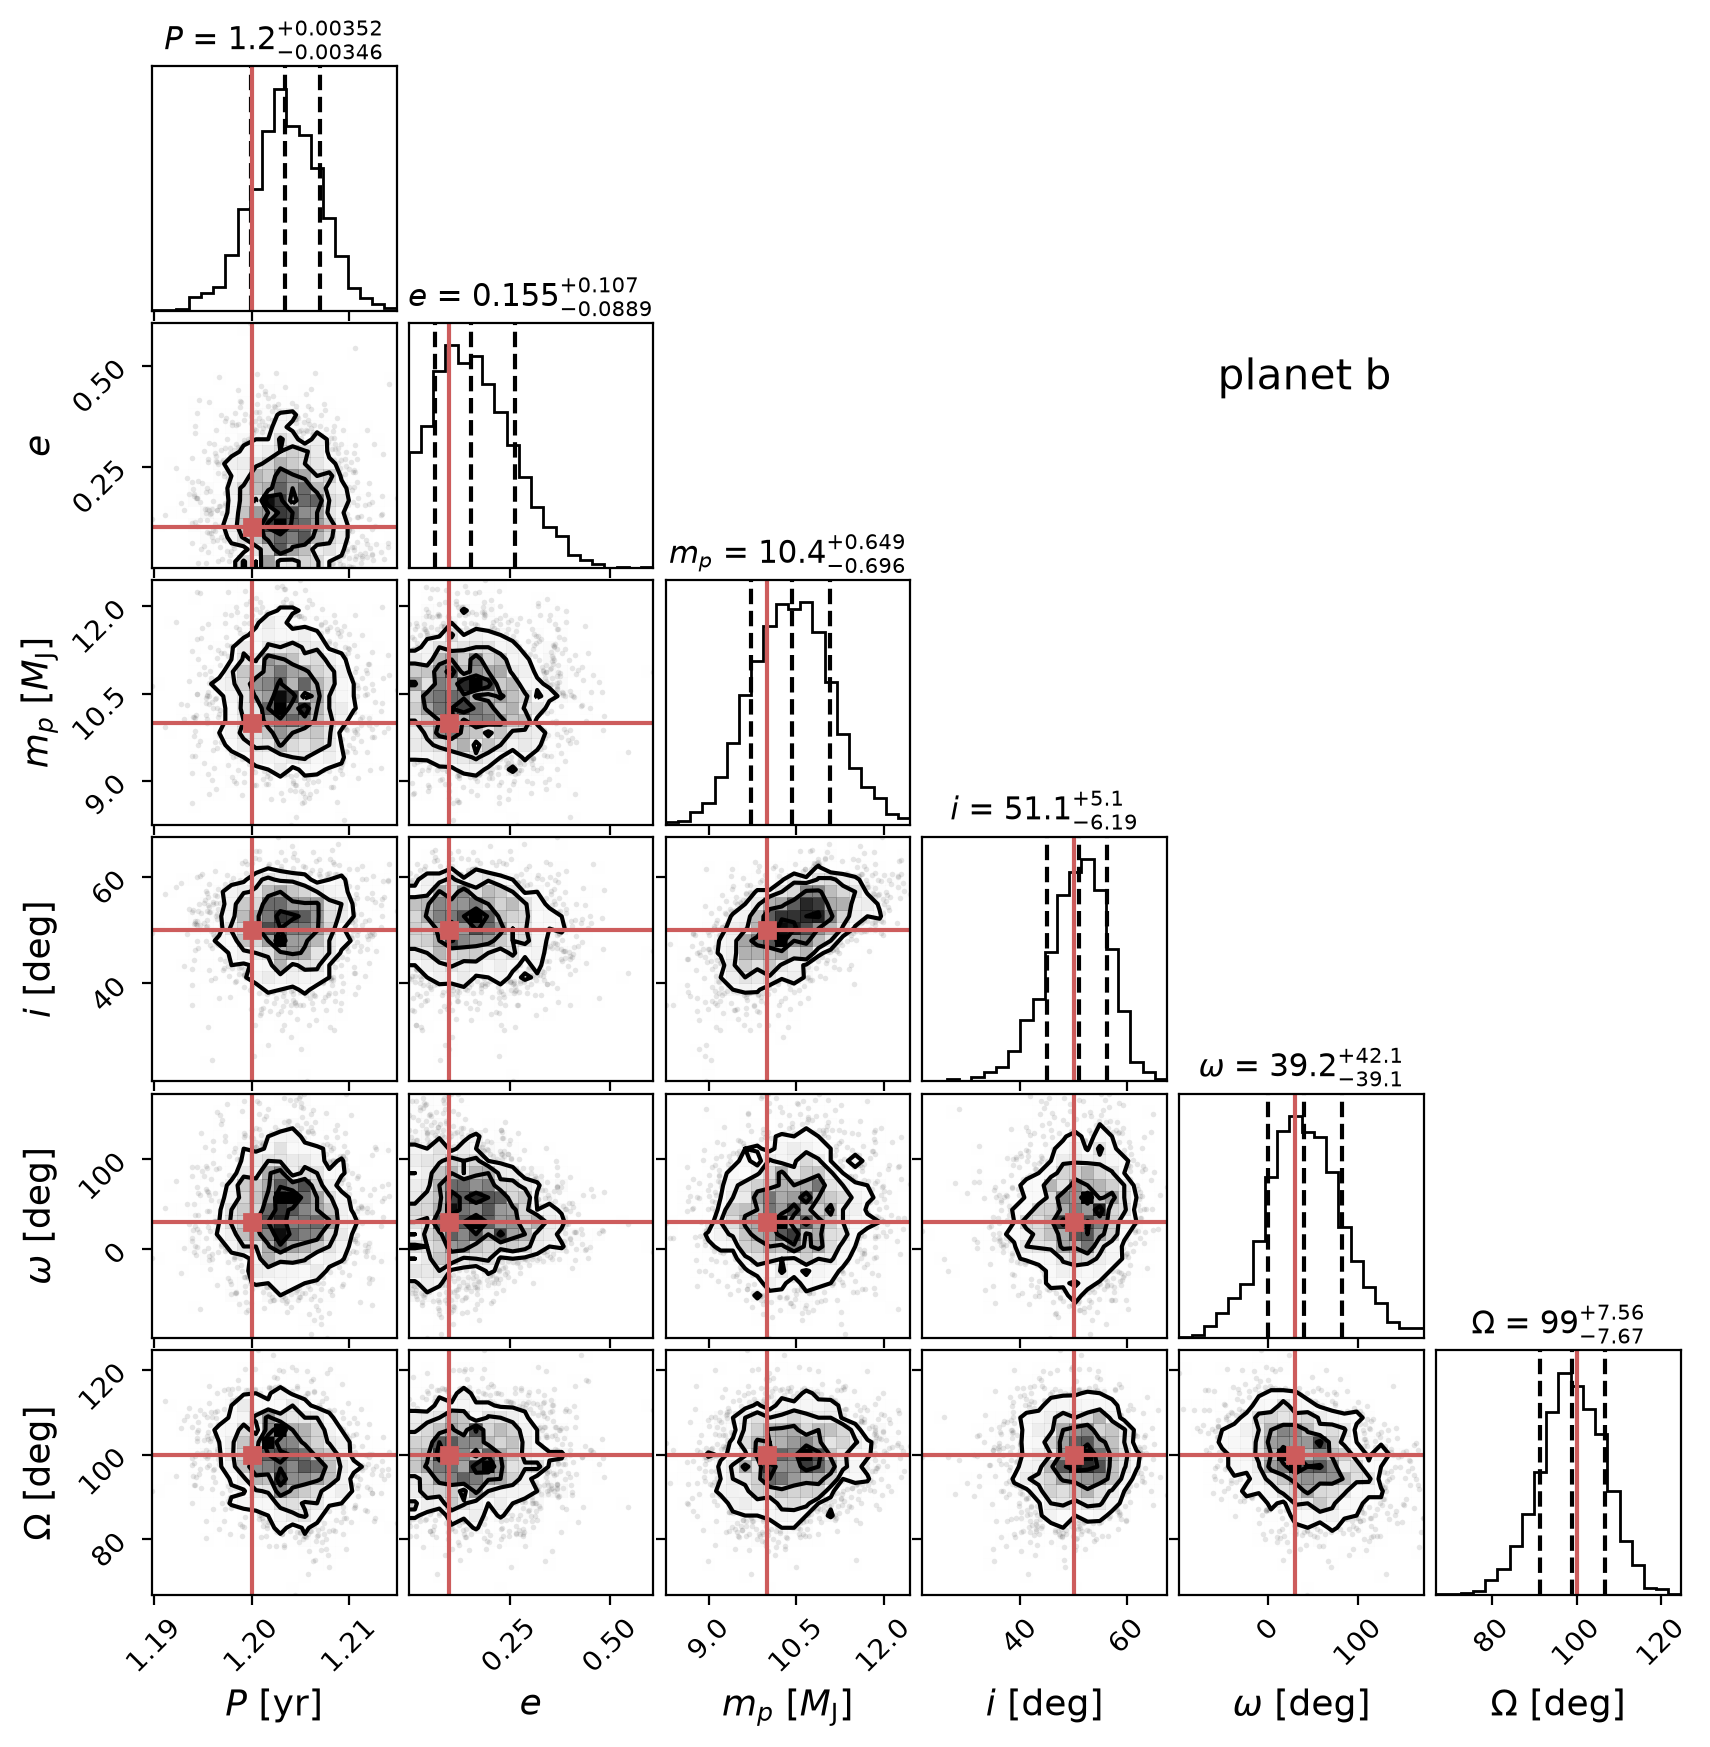

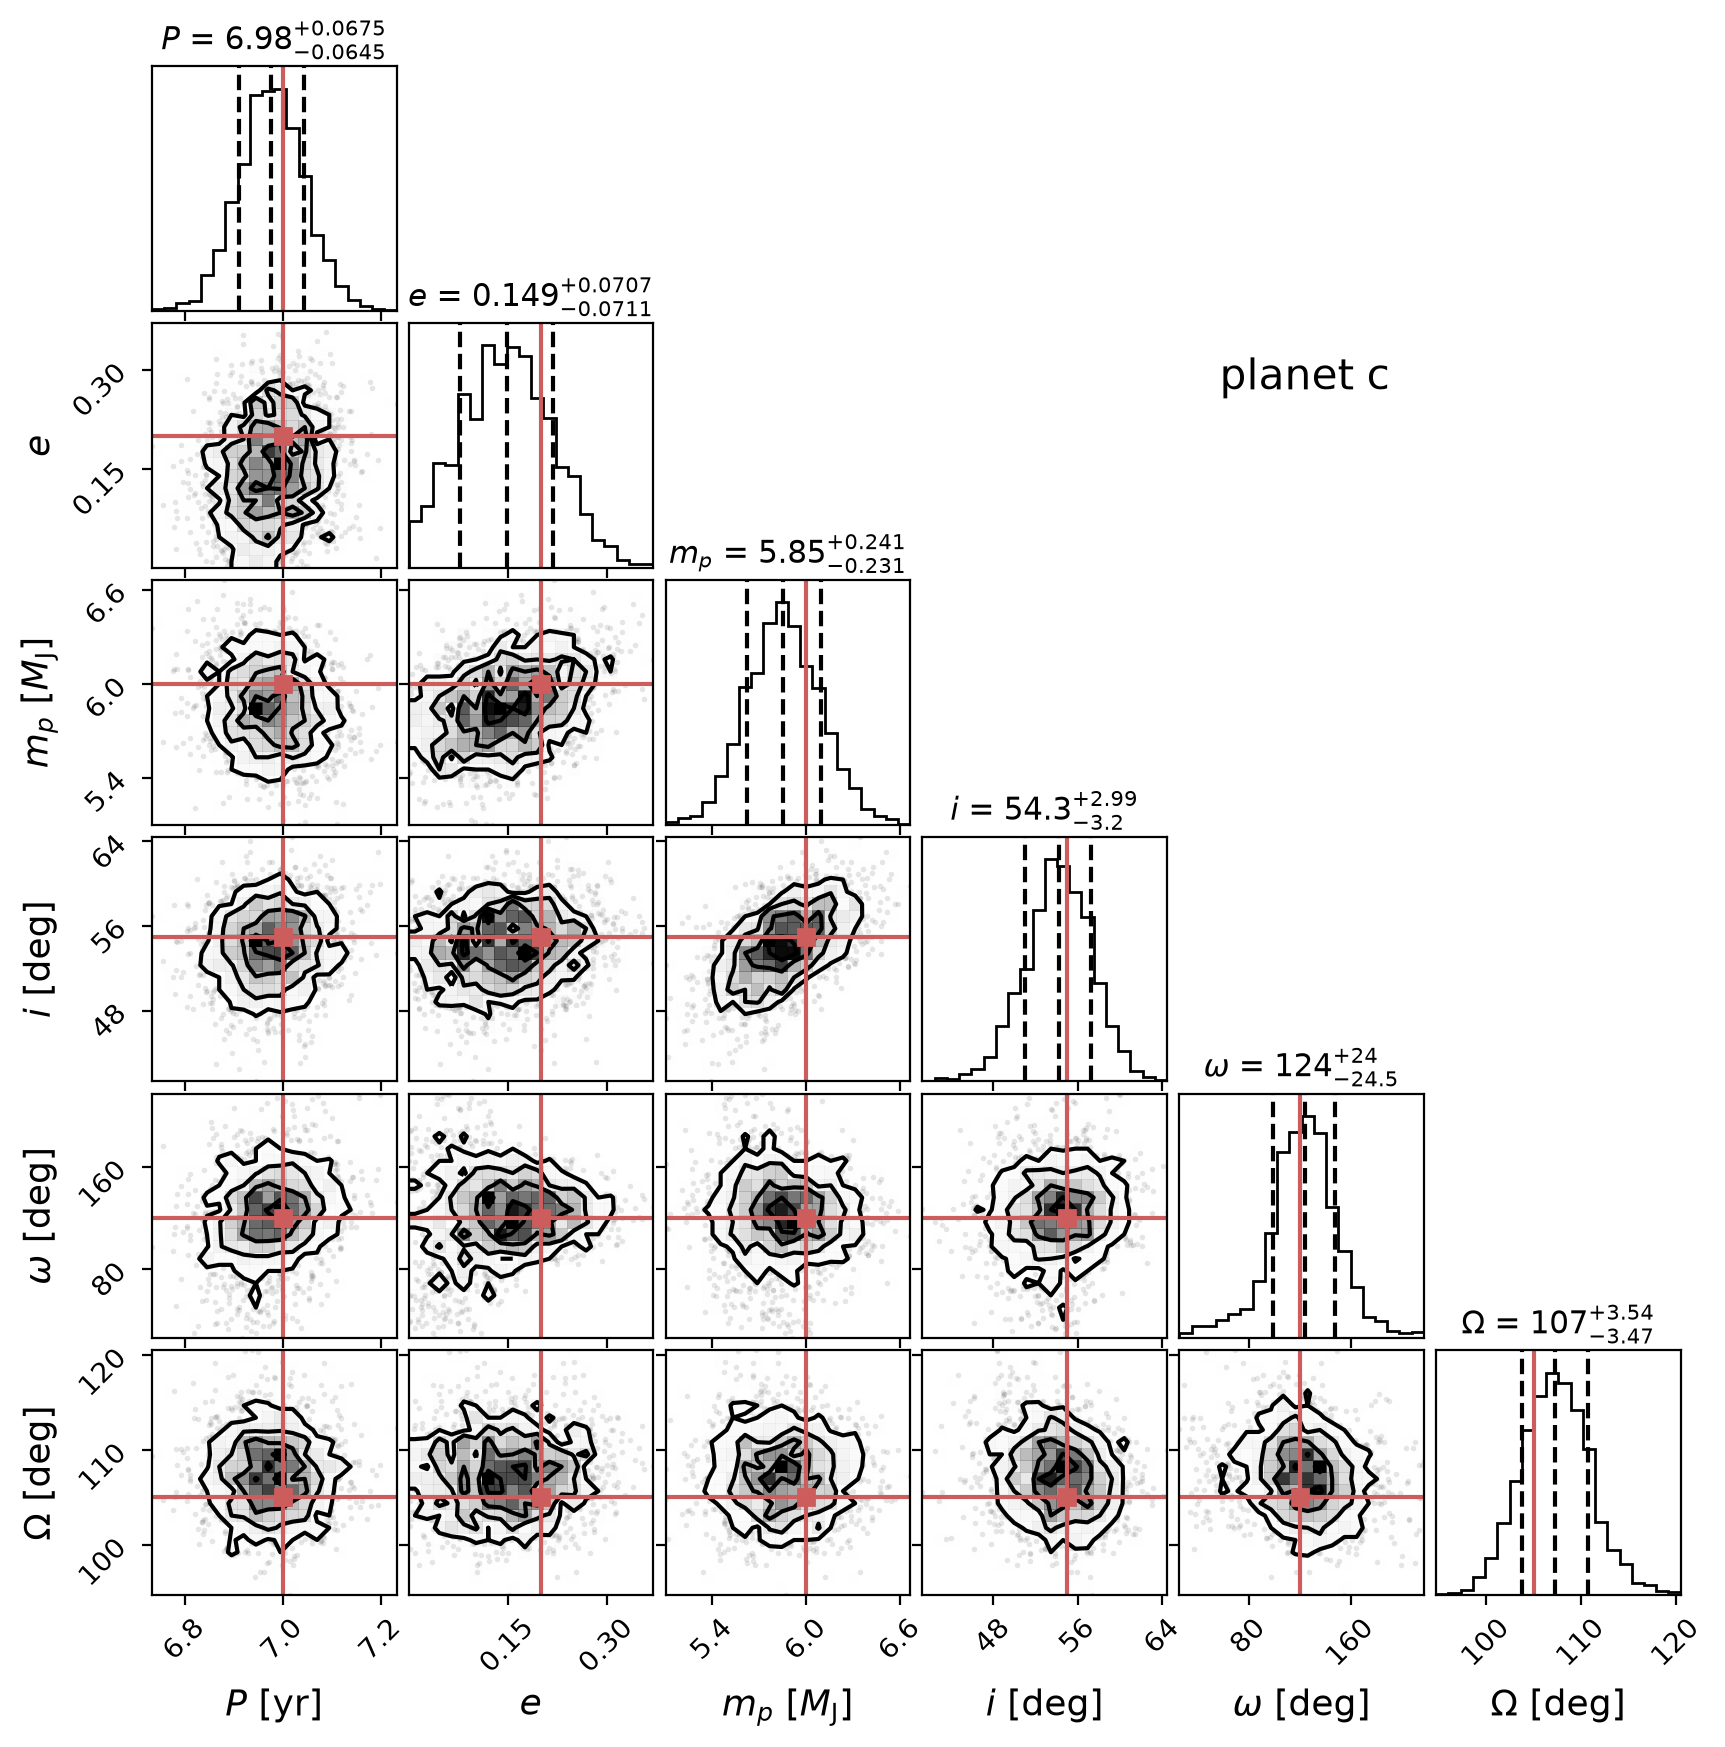

In [9]:
plx_s = samples[:, 2]
derived = []
for i, (planet, fit) in enumerate(zip(planets, res['planets'])):
    k = 5 + 7*i  # this planet's parameters: P, e, phi_p, A, B, F, G
    P_s, e_s = samples[:, k], samples[:, k + 1]
    a0_s, Omega_s, w_s, inc_s = gaiamock.get_Campbell_elements(*samples[:, k + 3:k + 7].T)
    m_s = gmp.get_dark_companion_mass(a0_mas=a0_s, period=P_s, parallax=plx_s, m1=m_star)
    w_s = fit['w'] + np.angle(np.exp(1j*(w_s - fit['w'])))  # w is an angle: keep it continuous around the best fit
    derived.append(np.column_stack([P_s/365.25, e_s, m_s/M_JUP, np.degrees(inc_s), np.degrees(w_s), np.degrees(Omega_s)]))

    labels = [r'$P$ [yr]', r'$e$', r'$m_p$ [$M_\mathrm{J}$]', r'$i$ [deg]', r'$\omega$ [deg]', r'$\Omega$ [deg]']
    titles = [r'$P$', r'$e$', r'$m_p$', r'$i$', r'$\omega$', r'$\Omega$']
    truths = [planet['period']/365.25, planet['ecc'], planet['m_planet']/M_JUP, np.degrees(planet['inc']), np.degrees(planet['w']), np.degrees(planet['Omega'])]
    fig = corner.corner(derived[i], labels=labels, titles=titles, truths=truths, truth_color='indianred',
                        quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt='.3g', max_n_ticks=3, labelpad=0.08,
                        label_kwargs=dict(fontsize=13), title_kwargs=dict(fontsize=11))
    fig.set_size_inches(8.5, 8.5)
    fig.suptitle(f'planet {names[i]}', fontsize=15, x=0.75, y=0.8)
    plt.show()

In [10]:
# the posterior widths agree with the fit's uncertainties
for i, fit in enumerate(res['planets']):
    for label, s, sigma_fit in [('P [yr]', derived[i][:, 0], fit['sig_period']/365.25), ('e', derived[i][:, 1], fit['sig_ecc']),
                                ('m_p [M_Jup]', derived[i][:, 2], fit['sig_m_planet']/M_JUP), ('inc [deg]', derived[i][:, 3], np.degrees(fit['sig_inc']))]:
        lo, med, hi = np.percentile(s, [16, 50, 84])
        print(f'planet {names[i]} {label:12s} MCMC {med:.3f} (+{hi - med:.3f} / -{med - lo:.3f});  fit uncertainty {sigma_fit:.3f}')
lo, med, hi = np.percentile(1e3*samples[:, -1], [16, 50, 84])
print(f'astrometric jitter: {med:.1f} (+{hi - med:.1f} / -{med - lo:.1f}) microarcsec')

planet b P [yr]       MCMC 1.203 (+0.004 / -0.003);  fit uncertainty 0.003
planet b e            MCMC 0.155 (+0.107 / -0.089);  fit uncertainty 0.085
planet b m_p [M_Jup]  MCMC 10.421 (+0.649 / -0.696);  fit uncertainty 0.605
planet b inc [deg]    MCMC 51.105 (+5.098 / -6.186);  fit uncertainty 5.059
planet c P [yr]       MCMC 6.976 (+0.067 / -0.064);  fit uncertainty 0.058
planet c e            MCMC 0.149 (+0.071 / -0.071);  fit uncertainty 0.053
planet c m_p [M_Jup]  MCMC 5.854 (+0.241 / -0.231);  fit uncertainty 0.200
planet c inc [deg]    MCMC 54.250 (+2.986 / -3.201);  fit uncertainty 2.683
astrometric jitter: 47.5 (+9.3 / -10.3) microarcsec
